# Train the card detector

Choose axis boxes, oriented boxes, or four corners with a shared frozen DINOv3 ConvNeXt Tiny backbone. Set `fast_dev_run = False` for full training.


In [1]:
import json
from pathlib import Path
from datetime import datetime

import cv2
import lightning.pytorch as pl
import wandb
import torch
from lightning.pytorch.callbacks import EarlyStopping, LearningRateMonitor, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger
from set_master.training.logging import create_wandb_logger

from set_master.training.data import CardDataModule
from set_master.training.callbacks import EpochEvaluation
from set_master.training.model import DEFAULT_REPO, DEFAULT_WEIGHTS
from set_master.training.config import DetectorConfig, DetectorVariant
from set_master.training.models.factory import create_detector, load_detector
from set_master.training.evaluation import prediction_overlay
from set_master.paths import PROJECT_ROOT, REAL_TESTSET_DIR, RUNS_DIR, SYNTHETIC_DATASETS_DIR
from set_master.visualization import display_image

print(f'Project: {PROJECT_ROOT}')
print(f'CUDA available: {torch.cuda.is_available()}')


Project: /home/florian/src/python/set-master
CUDA available: True


## Settings

Set `dataset_run` to the run you want to train on. With `val_data = None`, 10% of images are reserved for validation. Training samples a new subset each epoch; set `train_images_per_epoch = None` to use all training images.

Choose `variant`. The experiment name includes its type and timestamp. Geometry experiments require corner and oriented-box annotations.


In [2]:
variant = DetectorVariant.BOX  # BOX, ORIENTED, or CORNERS
experiment_name = f'{variant.value}_{datetime.now():%Y%m%d_%H%M%S_%f}'
dataset_run = 'reference_5to15cards_v1'
train_data = SYNTHETIC_DATASETS_DIR / dataset_run
val_data = None
val_fraction = 0.1
train_images_per_epoch = 200
test_data = REAL_TESTSET_DIR
augment = True
wandb_url = 'http://localhost:8080'
wandb_project = 'set-master'
wandb_entity = None

early_stopping_patience = 5
early_stopping_min_delta = 0.001
eval_score_threshold = 0.75
eval_iou_threshold = 0.5
validation_overlay_ids = None  # All validation images; set a list of IDs to limit.
test_overlay_ids = None  # All real images; set a list of IDs to limit.

weights_path = DEFAULT_WEIGHTS
repo_path = DEFAULT_REPO
output_dir = RUNS_DIR / 'card_detector' / variant.value / experiment_name
resume_checkpoint = None

batch_size = 4
num_workers = 0
epochs = 20
learning_rate = 1e-3
weight_decay = 1e-4
min_size = 640
max_size = 1280
accelerator = 'gpu'
precision = '32-true'
seed = 42
fast_dev_run = False


## Data preview

Ground-truth boxes are green.


Seed set to 42


Training pool: 900 images
Training images per epoch: 200
Validation images: 100
Real test images: 13
Validation image IDs: [543, 619, 817, 69, 95, 216, 61, 586, 943, 166, 969, 830, 187, 662, 526, 983, 316, 53, 642, 798, 50, 41, 732, 261, 468, 564, 252, 596, 300, 188, 743, 998, 532, 803, 460, 350, 696, 160, 335, 51, 547, 197, 874, 182, 796, 434, 808, 692, 54, 625, 821, 441, 339, 328, 563, 375, 312, 198, 21, 378, 787, 185, 513, 860, 407, 272, 912, 630, 952, 483, 568, 634, 721, 729, 251, 85, 584, 397, 419, 298, 535, 246, 481, 171, 911, 601, 498, 383, 892, 68, 768, 733, 162, 235, 186, 776, 826, 927, 854, 32]


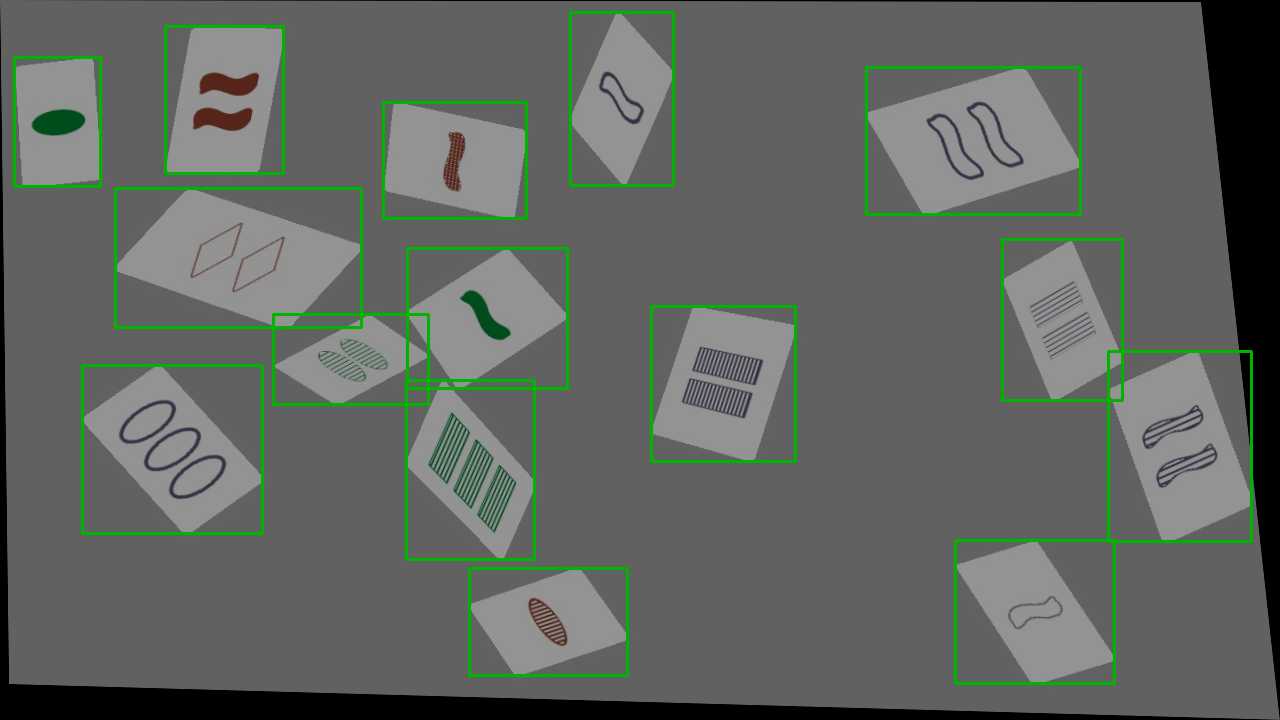

In [3]:
if not (train_data / 'annotations.json').is_file():
    raise FileNotFoundError('Choose a generated dataset in train_data, or create one with generate_synthetic_dataset.ipynb.')
if batch_size < 1 or num_workers < 0 or not 0 < min_size <= max_size:
    raise ValueError('Require batch_size > 0, num_workers >= 0 and 0 < min_size <= max_size.')

pl.seed_everything(seed, workers=True)
data = CardDataModule(
    train_root=train_data, val_root=val_data, batch_size=batch_size,
    num_workers=num_workers, val_fraction=val_fraction, seed=seed, variant=variant, test_root=test_data, augment=augment,
    train_images_per_epoch=train_images_per_epoch,
)
data.setup('fit')
print(f'Training pool: {len(data.train_dataset)} images')
print(f"Training images per epoch: {data.split_manifest['train_images_per_epoch']}")
print(f'Validation images: {len(data.val_dataset)}')
print(f'Real test images: {len(data.test_dataset) if data.test_dataset is not None else 0}')
print('Validation image IDs:', data.split_manifest['val_image_ids'])

sample_image, sample_target = data.train_dataset[0]
preview = cv2.cvtColor(sample_image.mul(255).byte().permute(1, 2, 0).numpy(), cv2.COLOR_RGB2BGR)
for x1, y1, x2, y2 in sample_target['boxes'].int().tolist():
    cv2.rectangle(preview, (x1, y1), (x2 - 1, y2 - 1), (0, 180, 0), 2)
display_image(preview)


## Model


In [4]:
model = create_detector(
    DetectorConfig(variant, learning_rate, weight_decay, min_size, max_size),
    weights_path=weights_path, repo_path=repo_path,
    initialize_pretrained=resume_checkpoint is None,
)
trainable = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
frozen = sum(parameter.numel() for parameter in model.parameters() if not parameter.requires_grad)
print(f'Trainable parameters: {trainable:,}')
print(f'Frozen parameters: {frozen:,}')


Trainable parameters: 17,229,849
Frozen parameters: 27,820,128


## Logging and checkpoints

Early stopping uses synthetic validation AP. Real test metrics are tracked separately after every epoch. All validation and real-image overlays are saved by default.


In [5]:
logger = CSVLogger(str(output_dir), name='')
logger.log_hyperparams(model.hparams)
run_dir = Path(logger.log_dir)
run_dir.mkdir(parents=True, exist_ok=True)
tracker = create_wandb_logger(
    run_dir, experiment_name, variant, wandb_url, wandb_project, wandb_entity,
)
tracker.log_hyperparams(model.hparams)
config = {
    'variant': variant.value, 'experiment_name': experiment_name, 'augment': augment,
    'wandb_url': wandb_url, 'wandb_project': wandb_project, 'wandb_entity': wandb_entity,
    'test_data': str(test_data) if test_data is not None else None,
    'early_stopping_patience': early_stopping_patience, 'early_stopping_min_delta': early_stopping_min_delta,
    'eval_score_threshold': eval_score_threshold, 'eval_iou_threshold': eval_iou_threshold,
    'validation_overlay_ids': validation_overlay_ids, 'test_overlay_ids': test_overlay_ids,
    'train_data': str(train_data), 'val_data': str(val_data) if val_data else None,
    'val_fraction': val_fraction, 'train_images_per_epoch': train_images_per_epoch, 'weights_path': str(weights_path), 'repo_path': str(repo_path),
    'batch_size': batch_size, 'num_workers': num_workers, 'epochs': epochs,
    'learning_rate': learning_rate, 'weight_decay': weight_decay,
    'min_size': min_size, 'max_size': max_size, 'accelerator': accelerator,
    'precision': precision, 'seed': seed, 'fast_dev_run': fast_dev_run,
    'resume_checkpoint': str(resume_checkpoint) if resume_checkpoint else None,
}
tracker.log_hyperparams(config)
(run_dir / 'config.json').write_text(json.dumps(config, indent=2) + '\n')
(run_dir / 'split.json').write_text(json.dumps(data.split_manifest, indent=2) + '\n')

monitor = 'val/map' if variant == DetectorVariant.BOX else 'val/geometry_map'
checkpoint = ModelCheckpoint(
    dirpath=run_dir / 'checkpoints', monitor=monitor, mode='max',
    save_top_k=1, save_last=True, filename='epoch-{epoch:02d}', auto_insert_metric_name=False,
)
early_stopping = EarlyStopping(
    monitor=monitor, mode='max', patience=early_stopping_patience,
    min_delta=early_stopping_min_delta, check_on_train_epoch_end=False, verbose=True,
)
epoch_evaluation = EpochEvaluation(
    run_dir, tracker, data.test_dataset,
    validation_overlay_ids=validation_overlay_ids, test_overlay_ids=test_overlay_ids,
    score_threshold=eval_score_threshold, iou_threshold=eval_iou_threshold,
)
trainer = pl.Trainer(
    max_epochs=epochs, accelerator=accelerator, devices=1, precision=precision,
    logger=[logger, tracker], callbacks=[epoch_evaluation, early_stopping, LearningRateMonitor(logging_interval='epoch'), checkpoint], gradient_clip_val=1.0,
    log_every_n_steps=1, fast_dev_run=fast_dev_run, default_root_dir=str(output_dir),
)
print(f'Run directory: {run_dir}')
print('Mode:', 'one-batch smoke check' if fast_dev_run else 'full training')


wandb: Loading settings from /home/florian/.config/wandb/settings
wandb: [wandb.login()] Loaded credentials for http://localhost:8080 from /home/florian/.netrc.
wandb: Currently logged in as: florian to http://localhost:8080. Use `wandb login --relogin` to force relogin


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Run directory: /home/florian/src/python/set-master/runs/card_detector/box/box_20261010_140758_801631/version_0
Mode: full training


wandb: WARNING Artifact "source-set-master-_home_florian_src_python_set-master_notebooks_train_card_detector.ipynb" already exists with the same content. No new version will be created.


## Live metrics

Open the W&B run to view losses, validation and real metrics, startup data grids, and prediction images.


In [6]:
from IPython.display import Markdown, display

display(Markdown(f'[Open W&B dashboard]({tracker.experiment.url})'))


[Open W&B dashboard](http://localhost:8080/florian/set-master/runs/0u3ecrga)

## Train


In [7]:
trainer.fit(model, datamodule=data, ckpt_path=resume_checkpoint)

print('Final metrics:')
for name, value in trainer.callback_metrics.items():
    print(f'  {name}: {value.item():.4f}')
if checkpoint.best_model_path:
    print(f'Best checkpoint: {checkpoint.best_model_path}')
    print(f'Last checkpoint: {checkpoint.last_model_path}')
wandb.finish()


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type                 | Params | Mode  | FLOPs
------------------------------------------------------------------
0 | detector | FasterRCNN           | 45.0 M | train | 0    
1 | box_map  | MeanAveragePrecision | 0      | train | 0    
------------------------------------------------------------------
17.2 M    Trainable params
27.8 M    Non-trainable params
45.0 M    Total params
180.200   Total estimated model params size (MB)
40        Modules in train mode
151       Modules in eval mode
0         Total Flops


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/florian/src/python/set-master/.venv/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/florian/src/python/set-master/.venv/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
/home/florian/src/python/set-master/.venv/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
/home/florian/src/python/set-master/.venv/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.p

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...


Detected KeyboardInterrupt, attempting graceful shutdown ...


SystemExit: 1

/home/florian/src/python/set-master/.venv/lib/python3.13/site-packages/IPython/core/interactiveshell.py:3707: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


Error in callback <bound method _WandbInit._post_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x74f69057a900>> (for post_run_cell), with arguments args (<ExecutionResult object at 74f69057ec60, execution_count=7 error_before_exec=None error_in_exec=1 info=<ExecutionInfo object at 74f69057e990, raw_cell="trainer.fit(model, datamodule=data, ckpt_path=resu.." transformed_cell="trainer.fit(model, datamodule=data, ckpt_path=resu.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/home/florian/src/python/set-master/notebooks/train_card_detector.ipynb#X53sZmlsZQ%3D%3D> result=None>,),kwargs {}:


MailboxClosedError: 

## Predictions

Ground truth is green; predictions are red.


In [ ]:
score_threshold = 0.75
if checkpoint.best_model_path:
    prediction_model = load_detector(Path(checkpoint.best_model_path), repo_path)
else:
    prediction_model = model.eval()

image, target = data.val_dataset[0]
with torch.inference_mode():
    prediction = prediction_model([image.to(prediction_model.device)])[0]
display_image(prediction_overlay(image, target, prediction, score_threshold))


AttributeError: 'CocoCardDataset' object has no attribute 'augmentation'